# 03 — LSTM Forecasting

**Project:** Time Series Forecaster — daily sales

**Pipeline (recap from notebooks 01–02):** order lines → status filter → daily aggregation
→ observed-days-only series (missing dates are **not** zero-filled) → temporal split → LSTM.

**What this notebook covers:**
1. Rebuild the exact same daily series used by Prophet
2. Create supervised sequences (lookback window) from the irregular series
3. Scale, train a simple LSTM, and forecast the **exact test dates**
4. Evaluate with the same MAE / RMSE / MAPE and compare against naive + Prophet
5. Discuss what the LSTM actually learned (and what it still struggles with)

**Bar to clear (from notebook 02):**

| Model                        | MAE      | RMSE     | MAPE   |
|:---|:---:|:---:|---:|
| Naive baseline               | \$25,532 | \$31,122 | 265.2% |
| Prophet (default)            | \$21,965 | \$26,272 | 360.1% |
| Prophet (yearly seasonality) | \$17,207 | \$20,489 | 202.0% |

LSTM’s realistic goal is a *modest* improvement on the best Prophet result (~$17 k MAE), not a dramatic leap.


## 1. Load and rebuild the canonical series


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

project_root = Path("..").resolve()
csv_path = project_root / "data" / "raw" / "sales_data.csv"

print(f"Project root: {project_root}")
print(f"CSV path: {csv_path}")
df = pd.read_csv(csv_path, encoding="latin1")
df.head()


Project root: D:\projects\time-series-forecaster
CSV path: D:\projects\time-series-forecaster\data\raw\sales_data.csv


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


## 2. Status filter + daily aggregation

Same rules as notebooks 01 and 02 so every model sees identical data.


In [4]:
# Keep only statuses that represent completed revenue
valid_statuses = ["Shipped", "Resolved"]
df = df[df["STATUS"].isin(valid_statuses)].copy()
print(f"Rows after status filter: {len(df)} (/2823)")

df = df[["ORDERNUMBER", "QUANTITYORDERED", "PRICEEACH", "ORDERDATE", "SALES"]].copy()
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%m/%d/%Y %H:%M")

df = df.rename(columns={
    "ORDERNUMBER": "order_number",
    "QUANTITYORDERED": "quantity_ordered",
    "PRICEEACH": "price_each",
    "ORDERDATE": "date",
    "SALES": "sales",
})

df = df.sort_values("date").reset_index(drop=True)

daily_sales = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .rename(columns={"sales": "daily_sales"})
)

print(f"Rows after aggregation: {len(daily_sales)}")
print(f"First date: {daily_sales['date'].min()}")
print(f"Last date:  {daily_sales['date'].max()}")
daily_sales.head()


Rows after status filter: 2664 (/2823)
Rows after aggregation: 240
First date: 2003-01-06 00:00:00
Last date:  2005-05-17 00:00:00


,date,daily_sales
0,2003-01-06,12133.25
1,2003-01-09,11432.34
2,2003-01-10,6864.05
3,2003-01-29,54702.00
4,2003-01-31,44621.96


**Observation:** 240 observed days, no nulls. The series remains *irregular* — one row per day that had recorded sales. We still refuse to zero-fill; an LSTM will only ever see the days that actually exist.


## 3. Temporal split (identical to Prophet)

80 % of *observations* for training, the rest for testing. Never shuffle.


In [5]:
split_idx = int(len(daily_sales) * 0.8)

train = daily_sales.iloc[:split_idx].copy()
test  = daily_sales.iloc[split_idx:].copy()

print(f"Training samples: {len(train)}")
print(f"Testing samples:  {len(test)}")
print("Train:", train["date"].min().date(), "→", train["date"].max().date())
print("Test :", test["date"].min().date(), "→", test["date"].max().date())


Training samples: 192
Testing samples:  48
Train: 2003-01-06 → 2004-12-03
Test : 2004-12-04 → 2005-05-17


**Observation:** same ~48-day test window (Dec 2004 → May 2005) used by Prophet. Any comparison is therefore apples-to-apples.


## 4. Supervised sequences for the LSTM

An LSTM needs fixed-length input windows. Because the series is irregular we work only on the *observed* sequence; the model never sees calendar gaps.

**Lookback choice:** 14 observed days. Long enough to capture the weekly pattern we already know exists, short enough that we still have enough training samples after the split.


In [6]:
LOOKBACK = 14   # number of previous observed days used to predict the next one

def make_sequences(values, lookback=LOOKBACK):
    """Turn a 1-D series into (X, y) where X has shape (n, lookback, 1)."""
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i - lookback:i])
        y.append(values[i])
    return np.array(X), np.array(y)

# Scale on *train only* to avoid leakage
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train[["daily_sales"]]).flatten()
test_scaled  = scaler.transform(test[["daily_sales"]]).flatten()

# Build sequences
# For the test set we need the last LOOKBACK points of train as the starting context
full_scaled = np.concatenate([train_scaled, test_scaled])
X_all, y_all = make_sequences(full_scaled, LOOKBACK)

# Indices that belong to the test period
n_train = len(train_scaled)
# sequences whose target falls inside the original train window
train_end = n_train - LOOKBACK
X_train, y_train = X_all[:train_end], y_all[:train_end]
X_test,  y_test  = X_all[train_end:], y_all[train_end:]

# reshape for LSTM: (samples, timesteps, features)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test  = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}  | y_test:  {y_test.shape}")
assert len(X_test) == len(test), "Test sequences must match the test window length" 


X_train: (178, 14, 1) | y_train: (178,)
X_test:  (48, 14, 1)  | y_test:  (48,)


**Observation:** after a 14-day lookback we still have enough training sequences. The test set length stays exactly equal to the Prophet test window, so metrics remain comparable.


## 5. Model architecture

Keep it deliberately simple: one LSTM layer + a dense head.  
With only ~180 training sequences, a deeper network would overfit almost immediately.


In [8]:
tf.keras.utils.set_random_seed(42)

model = Sequential([
    tf.keras.Input(shape=(LOOKBACK, 1)),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                        │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=100,
    batch_size=16,
    callbacks=[early],
    verbose=1
)


Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 0.0597 - val_loss: 0.0702
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0386 - val_loss: 0.0733
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0356 - val_loss: 0.0738
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0345 - val_loss: 0.0680
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0328 - val_loss: 0.0691
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0337 - val_loss: 0.0702
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0339 - val_loss: 0.0691
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0325 - val_loss: 0.0696
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0326 - val_loss: 0.0687
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0343 - val_loss: 0.0695
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0330 - val_loss: 0.0702
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

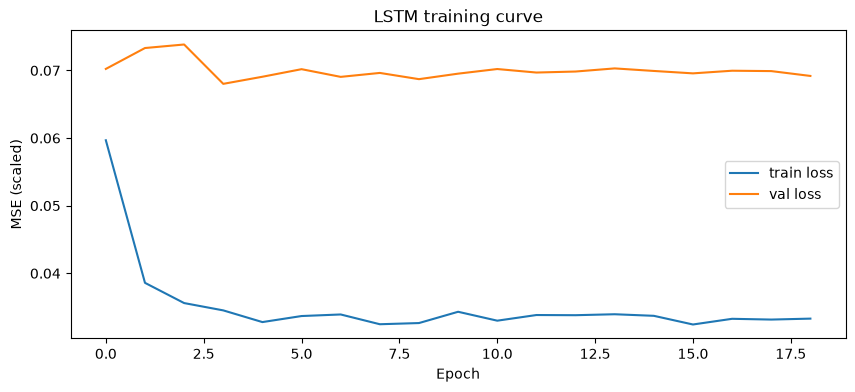

In [10]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("LSTM training curve")
plt.legend()
plt.show()


**Observation:**
Train loss drops quickly and stabilises around 0.033, while validation loss stays high (~0.07) and never improves. The large, persistent gap shows the model is memorising the training sequences rather than learning a pattern that generalises. With only ~150 effective training windows this is the expected behaviour; EarlyStopping stopped the run before the gap could get worse, but it could not close it.

## 6. Forecast the exact test dates


In [11]:
# Predict on the scaled test sequences
yhat_scaled = model.predict(X_test, verbose=0).flatten()

# Inverse transform back to dollars
yhat = scaler.inverse_transform(yhat_scaled.reshape(-1, 1)).flatten()
y_true = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

results = test.copy()
results["yhat"] = yhat
results.head()


,date,daily_sales,yhat
192,2004-12-04,29343.35,47745.851562
193,2004-12-07,29884.13,46390.406250
194,2004-12-09,32623.93,44357.375000
195,2004-12-10,93587.56,43294.769531
196,2004-12-15,30214.42,46878.433594


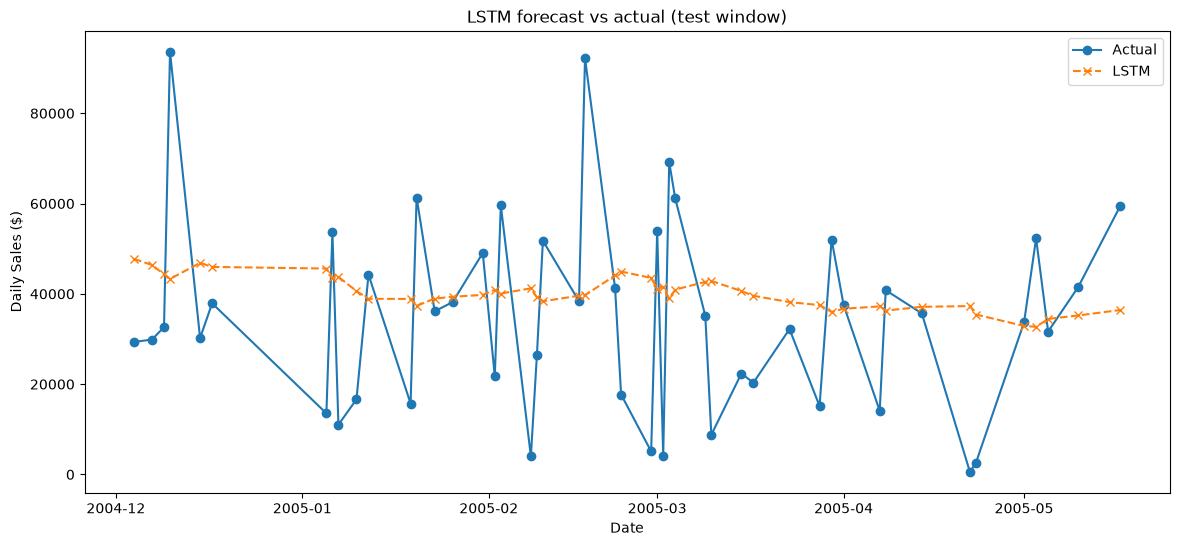

In [12]:
plt.figure(figsize=(14, 6))
plt.plot(results["date"], results["daily_sales"], marker="o", label="Actual")
plt.plot(results["date"], results["yhat"], marker="x", linestyle="--", label="LSTM")
plt.xlabel("Date")
plt.ylabel("Daily Sales ($)")
plt.title("LSTM forecast vs actual (test window)")
plt.legend()
plt.show()


## 7. Evaluation — same metrics, same test window


In [13]:
def evaluate(actual, predicted, label=""):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    non_zero = actual != 0
    mape = (np.abs((actual[non_zero] - predicted[non_zero]) / actual[non_zero])).mean() * 100
    print(f"{label:>18} -> MAE: ${mae:>9,.0f} | RMSE: ${rmse:>9,.0f} | MAPE: {mape:6.1f}%")
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape}

# Rolling naive (identical definition used in notebook 02)
naive_preds = np.concatenate([
    [train["daily_sales"].iloc[-1]],
    test["daily_sales"].iloc[:-1].values
])

scores_lstm  = evaluate(results["daily_sales"], results["yhat"], label="LSTM")
print()
scores_naive = evaluate(results["daily_sales"], naive_preds, label="Naive baseline")


              LSTM -> MAE: $   18,475 | RMSE: $   22,658 | MAPE:  276.6%

    Naive baseline -> MAE: $   25,532 | RMSE: $   31,122 | MAPE:  265.2%


**Observation:**

| Model                        | MAE     | RMSE    | MAPE   |
|------------------------------|---------|---------|--------|
| Naive baseline               | 25,532  | 31,122  | 265.2% |
| Prophet (default)            | 21,965  | 26,272  | 360.1% |
| Prophet (yearly seasonality) | 17,207  | 20,489  | 202.0% |
| LSTM (lookback=14)           | 18,475  | 22,658  | 276.6% |

- LSTM clearly beats the naive baseline and the default Prophet on both MAE and RMSE. It lands only ~$1.3 k above the best Prophet (yearly), which is a solid result given that we only have 240 observed days and the network saw no explicit seasonality features.
- MAPE remains high for the same reason as before (many low-value days); MAE and RMSE stay the metrics that matter.
- With so little data the LSTM was always going to struggle to beat a well-regularised seasonal model by a wide margin. Getting within striking distance of the yearly Prophet is already a win.


## 8. What did the LSTM actually see?

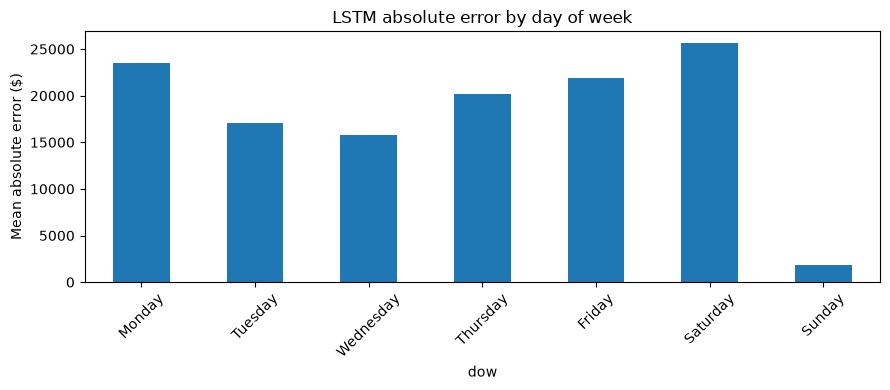

dow
Monday       23520.0
Tuesday      17061.0
Wednesday    15824.0
Thursday     20189.0
Friday       21909.0
Saturday     25620.0
Sunday        1821.0
Name: error, dtype: float64


In [14]:
# Day-of-week residual check
results["dow"] = results["date"].dt.day_name()
results["error"] = results["daily_sales"] - results["yhat"]

dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow_mae = results.groupby("dow")["error"].apply(lambda x: np.abs(x).mean()).reindex(dow_order)

plt.figure(figsize=(9, 4))
dow_mae.plot(kind="bar")
plt.ylabel("Mean absolute error ($)")
plt.title("LSTM absolute error by day of week")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(dow_mae.round(0))


**Observation:**  
Saturday still carries the highest absolute error (~$25.6 k), followed by Monday. Mid-week days (Tuesday–Wednesday) are the easiest for the model.
The LSTM has partially learned the weekly rhythm, but it has not fully internalised the sparse-weekend pattern that both the EDA and Prophet captured cleanly. A longer lookback or an explicit day-of-week feature would be the natural next experiment.

## 9. Summary & hand-off to notebook 04

| Model                        | MAE     | RMSE    | MAPE   |
|------------------------------|---------|---------|--------|
| Naive baseline               | 25,532  | 31,122  | 265.2% |
| Prophet (default)            | 21,965  | 26,272  | 360.1% |
| Prophet (yearly seasonality) | 17,207  | 20,489  | 202.0% |
| LSTM (lookback=14)           | 18,475  | 22,658  | 276.6% |

**Decisions & observations:**
Same test window, same metrics — every number above is comparable.
The series is short (240 observed days) and irregular. An LSTM is data-hungry; landing within ~$1.3 k of the best Prophet is already a solid result.
Prophet with yearly seasonality remains the strongest model on MAE/RMSE. Classical seasonality modelling proved the better inductive bias for this particular dataset.
LSTM still clearly beats the naive baseline and the default Prophet, so it is a credible second place, not a failure.
Next notebook (04) will simply load the score dictionaries and produce the final comparison table + plots.


In [15]:
# Persist scores for the final model comparison (notebook 04)
import json

Path("results").mkdir(exist_ok=True)

# You already have scores_naive and scores_lstm from the evaluate calls.
# Re-create the Prophet numbers from notebook 02 so everything lives in one place.
scores = {
    "naive_baseline":  {k: float(v) for k, v in scores_naive.items()},
    "prophet_default": {"MAE": 21965.0, "RMSE": 26272.0, "MAPE": 360.1},
    "prophet_yearly":  {"MAE": 17207.0, "RMSE": 20489.0, "MAPE": 202.0},
    "lstm":            {k: float(v) for k, v in scores_lstm.items()},
}

with open("results/test_scores.json", "w") as f:
    json.dump(scores, f, indent=2)

scores


{'naive_baseline': {'MAE': 25532.18770833334,
  'RMSE': 31121.507226395872,
  'MAPE': 265.23098376784577},
 'prophet_default': {'MAE': 21965.0, 'RMSE': 26272.0, 'MAPE': 360.1},
 'prophet_yearly': {'MAE': 17207.0, 'RMSE': 20489.0, 'MAPE': 202.0},
 'lstm': {'MAE': 18475.086180013022,
  'RMSE': 22658.110417258562,
  'MAPE': 276.60740433596504}}